# Lab 4: Ticket Escalation Classification
**Course:** ML and Big Data (Software stream)

Build and evaluate binary classifiers for a synthetic ticket-escalation dataset, choosing metrics and thresholds according to the cost of mistakes.

## 1. Load and inspect the data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay
)

df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [ ]:
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64


**Why classification?** The target `escalated` takes two values (0/1), so we predict a category, not a number.
**Positive class:** `escalated = 1`, the rare and costly event we want to catch (about 21% of tickets).

## 2. Train/test split (75/25, stratified, random_state=42)

In [ ]:
X = df.drop(columns="escalated")
y = df["escalated"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print("Train prevalence:", y_train.mean().round(3), "| Test prevalence:", y_test.mean().round(3))

(675, 5) (225, 5)
Train prevalence: 0.207 | Test prevalence: 0.204


## 3. Preprocessing pipelines

In [ ]:
num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocess = ColumnTransformer([("num", num_pipe, num_cols),
                                ("cat", cat_pipe, cat_cols)])

## 4. Fit the models

In [ ]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}
fitted, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)]).fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba) if name != "Majority baseline" else np.nan})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,NaN
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


## 5. Logistic regression: confusion matrix and ROC curve

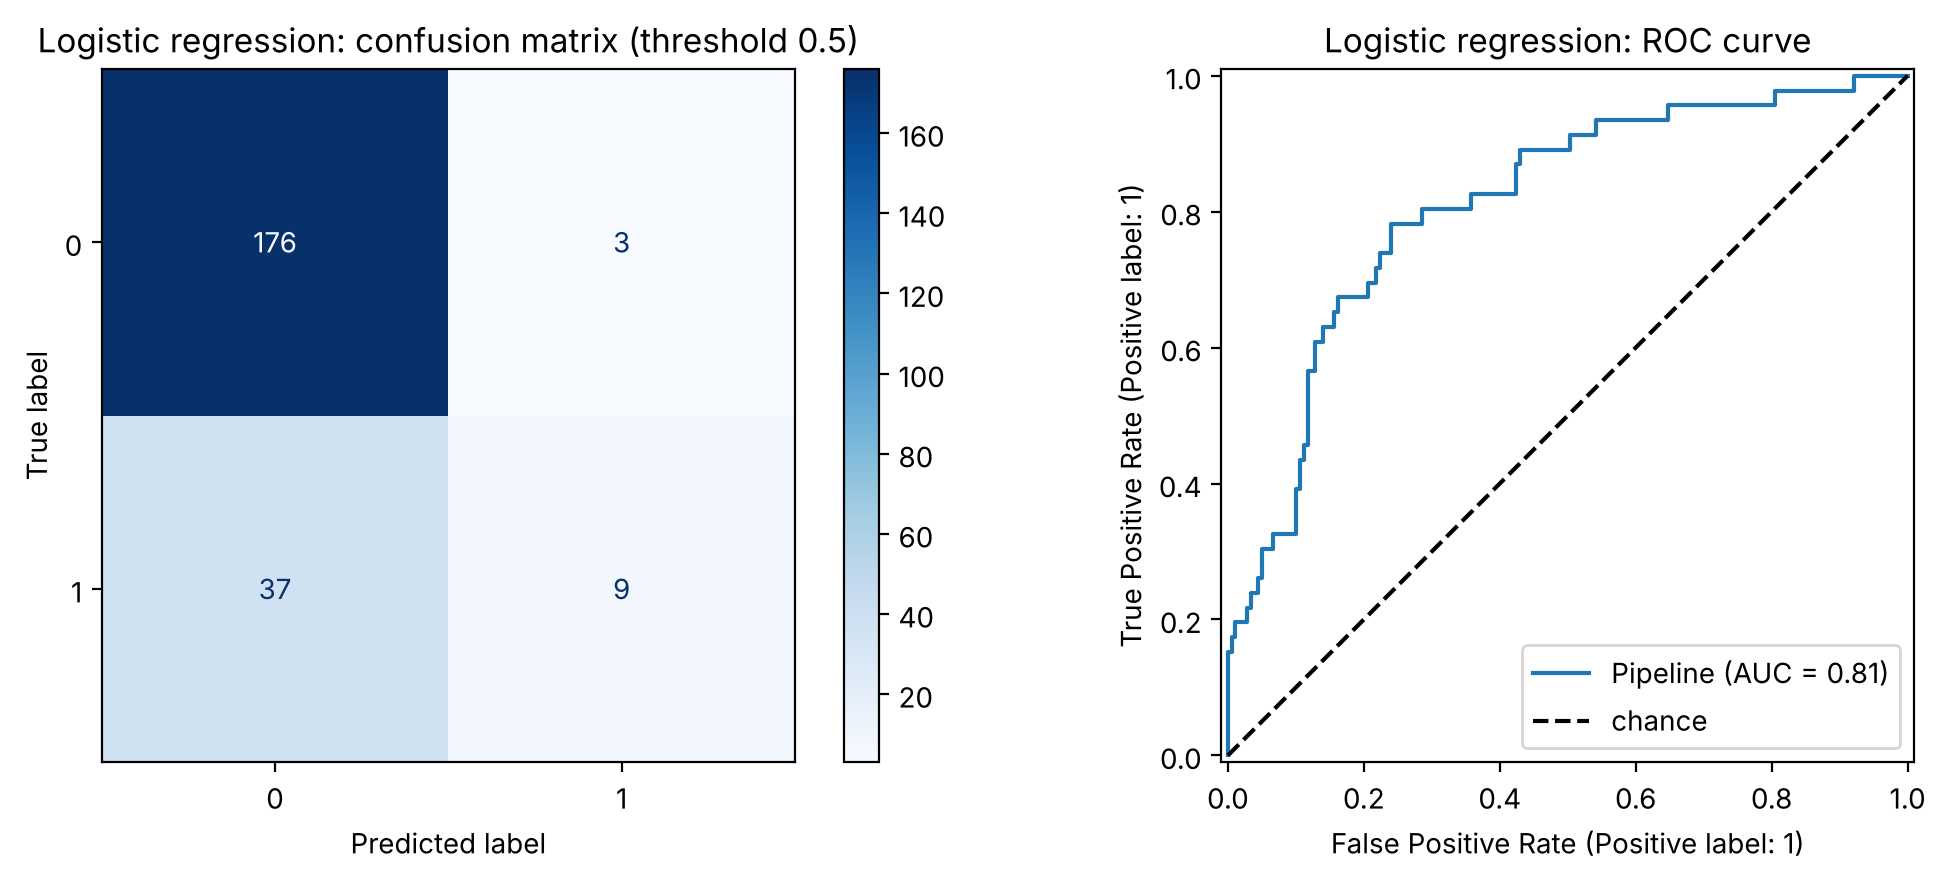

              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       225
weighted avg       0.81      0.82      0.78       225



In [ ]:
logit = fitted["Logistic regression"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_estimator(logit, X_test, y_test, ax=ax[0], cmap="Blues")
ax[0].set_title("Logistic regression: confusion matrix (threshold 0.5)")
RocCurveDisplay.from_estimator(logit, X_test, y_test, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", label="chance")
ax[1].set_title("Logistic regression: ROC curve"); ax[1].legend()
plt.tight_layout(); plt.show()
print(classification_report(y_test, logit.predict(X_test)))

## 6. Threshold analysis and cost (5 x FN + 1 x FP)

In [ ]:
proba = logit.predict_proba(X_test)[:, 1]
trows = []
for t in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    trows.append({"Threshold": t,
                  "Precision": precision_score(y_test, pred, zero_division=0),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "FP": fp, "FN": fn,
                  "Cost (5*FN + FP)": 5 * fn + fp})
thresholds = pd.DataFrame(trows).set_index("Threshold").round(3)
display(thresholds)
best_t = thresholds["Cost (5*FN + FP)"].idxmin()
print("Threshold with minimum cost:", best_t, "| cost =", thresholds.loc[best_t, "Cost (5*FN + FP)"])

,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
Threshold,,,,,,
0.2,0.429,0.783,0.554,48,10,98
0.3,0.549,0.609,0.577,23,18,113
0.4,0.571,0.261,0.358,9,34,179
0.5,0.750,0.196,0.310,3,37,188
0.6,1.000,0.065,0.122,0,43,215
0.7,0.000,0.000,0.000,0,46,230


Threshold with minimum cost: 0.2 | cost = 98


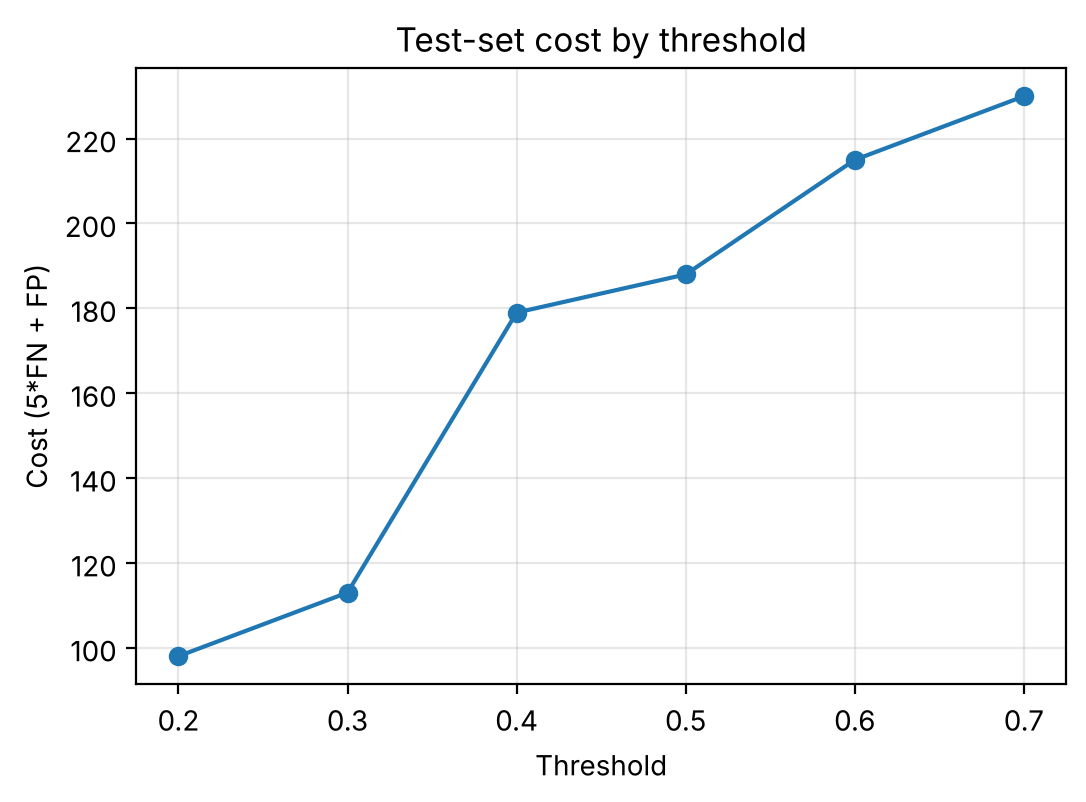

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(thresholds.index, thresholds["Cost (5*FN + FP)"], marker="o")
plt.xlabel("Threshold"); plt.ylabel("Cost (5*FN + FP)"); plt.title("Test-set cost by threshold"); plt.grid(alpha=.3)
plt.show()

## 7. Cross-validated tuning of k for k-NN (stratified 5-fold, F1)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_pipe = Pipeline([("prep", preprocess), ("clf", KNeighborsClassifier())])
gs = GridSearchCV(knn_pipe, {"clf__n_neighbors": [5, 9, 15, 21, 31]}, scoring="f1", cv=cv).fit(X_train, y_train)
cv_table = pd.DataFrame({"k": gs.cv_results_["param_clf__n_neighbors"],
                         "Mean CV F1": gs.cv_results_["mean_test_score"],
                         "Std": gs.cv_results_["std_test_score"]}).round(3)
display(cv_table)
print("Best k:", gs.best_params_)
tuned = gs.best_estimator_
pred = tuned.predict(X_test)
print("Tuned k-NN test F1:", round(f1_score(y_test, pred), 3), "| recall:", round(recall_score(y_test, pred), 3),
      "| precision:", round(precision_score(y_test, pred, zero_division=0), 3))

,k,Mean CV F1,Std
0,5,0.243,0.095
1,9,0.198,0.065
2,15,0.160,0.065
3,21,0.146,0.056
4,31,0.112,0.040


Best k: {'clf__n_neighbors': 5}
Tuned k-NN test F1: 0.203 | recall: 0.13 | precision: 0.462


## 8. Cross-validated comparison of all models (training set)

In [ ]:
cv_rows = []
for name, clf in models.items():
    if name == "Majority baseline":
        continue
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "recall", "precision", "roc_auc"])
    cv_rows.append({"Model": name, **{k: s[f"test_{k}"].mean() for k in ["precision", "recall", "f1", "roc_auc"]}})
pd.DataFrame(cv_rows).set_index("Model").round(3)

,precision,recall,f1,roc_auc
Model,,,,
Logistic regression,0.539,0.164,0.248,0.744
LDA,0.554,0.179,0.266,0.743
k-NN (k=15),0.458,0.100,0.160,0.681


## 9. Recommendation (300-500 words)

**Model choice.** I recommend logistic regression. At the default 0.5 threshold it ties with LDA on precision (0.75), recall (0.20), F1 (0.31) and has a marginally higher ROC-AUC (0.811 vs 0.809 on the test set, 0.744 vs 0.743 in cross-validation). It also gives well-behaved probabilities and interpretable coefficients. k-NN was clearly weaker (ROC-AUC 0.705; test F1 0.15 at k=15), and tuning k by cross-validated F1 chose k=5 but still only reached a test F1 of 0.20.

**Why not just use accuracy.** About 79% of tickets are not escalated, so the majority baseline scores 0.796 accuracy while catching no escalations at all. Logistic regression reaches only 0.822 accuracy at threshold 0.5, and it misses 37 of 46 escalated tickets. Accuracy hides this, so recall and cost matter more here.

**Threshold and error costs.** Using the illustrative cost of 5 for a missed escalation (FN) and 1 for a false alarm (FP), the best threshold on the test set was 0.20: 48 false positives and 10 false negatives, a cost of 98, compared with 188 at 0.50. Recall rises from 0.20 to 0.78 while precision falls from 0.75 to 0.43. The theoretical cost-sensitive threshold is 1/6, about 0.17, so 0.20 is consistent with theory, and I would recommend a threshold of about 0.2 and re-check it on new data. Because 0.20 is the lowest value in the grid, an even lower threshold might do slightly better.

**Limitations.** The cost figures are illustrative, not measured; the real FN:FP ratio should come from the business. The test set has only 46 positive tickets, so every metric is noisy, and choosing the threshold on the same test set makes the reported cost optimistic. The data is synthetic, ROC-AUC of about 0.81 means the model is useful but far from decisive, and missing values were filled with simple medians or most frequent categories, which may hide patterns in the missingness.

**Responsible use and checks before deployment.** A model like this should support, not replace, human triage. Low-priority or short-tenure customers could be systematically over- or under-flagged, so I would check performance by priority, channel and tenure group, calibrate the probabilities, use a time-based split on real tickets, monitor drift, and run it in shadow mode first. Over-escalation also has a cost in staff time, which should be reviewed together with the FP cost.

## 10. Questions

**Why is accuracy alone potentially misleading?** Most tickets (79%) don't get escalated. So a model that just says "no" every time gets 79% accuracy — it looks good but never actually catches the escalations. That's why we need other measures like precision, recall, F1, and ROC-AUC to see what the model really does.

**Which classifier has the strongest recall? Which has the strongest precision/F1?** At threshold 0.5, logistic regression and LDA tie: recall 0.196, precision 0.75, F1 0.31. k-NN (k=15) does worse on all three: recall 0.087, precision 0.50, F1 0.148. Logistic regression also has the best ROC-AUC (0.811).


**What changes when the threshold is lowered?** Lowering the threshold means more tickets get flagged as escalated. Good news: we catch more real escalations (recall goes up). Bad news: we also flag more tickets that won't escalate (precision goes down). In the table, going from 0.7 to 0.2 raises recall from 0 to 0.78, but precision drops to 0.43 and false positives jump from 0 to 48.



**Which threshold minimizes 5xFN + FP, and why might this be optimistic?** Threshold 0.20 gives the lowest cost (98), with 10 false negatives and 48 false positives. This is probably too good to be true because we picked the threshold by looking at the test set itself. With only 46 positive cases, the result is likely a bit lucky. The real cost on new data will probably be higher. We should pick the threshold using a separate validation set or cross-validation, then check the test set only once at the end.


**Prior, likelihood, posterior and evidence in the ticket scenario.**
- Prior P(escalated): Before we look at any ticket, about 21% of tickets escalate. That's our starting guess.
Likelihood P(x | escalated): If a ticket IS escalated, how common are its features (e.g. high complexity, high priority, phone channel)?
Evidence P(x): How common are those features across ALL tickets, whether they escalate or not.
Posterior P(escalated | x): After seeing the ticket's features, what's the updated chance it escalates? Formula: P(x | escalated) × P(escalated) / P(x).

**Expected cost with P(escalated | x) = 0.30, FP cost 1, FN cost 5.**
-Escalate: If the ticket wouldn't have escalated (70% chance), we made a false positive. Cost = 0.70 × 1 = 0.70.
Don't escalate: If the ticket WOULD have escalated (30% chance), we missed it. Cost = 0.30 × 5 = 1.50.
Decision: 0.70 < 1.50, so we escalate.70**.
- Do not escalate: it is a false negative if the ticket would escalate, which has probability 0.30, so expected cost = 0.30 x 5 = **1.50**.
- Escalating is cheaper (0.70 < 1.50), so we should escalate.

*Threshold derivation:* We escalate when: (1 − p) × C_FP < p × C_FN. Solving for p gives p > C_FP / (C_FP + C_FN) = 1 / 6 ≈ 0.167. So any ticket with a probability above 0.167 should be escalated. That's why the best threshold in the table is so low (0.20 was the lowest value we tested).


**Which model would you recommend and what further checks are needed?** Use logistic regression with a threshold around 0.2. Before going live, we should check:

Is the probability well-calibrated (does 0.30 really mean 30%)?
Does it work equally well for all groups?
Does it still work on data from a different time period?
Was the threshold tuned on validation data, not the test set?
Is the 5:1 cost ratio actually correct in practice?
Will performance drift over time?
Run it in "shadow mode" first (make predictions but don't act on them) to confirm it works in production.